# Tree workbench

A free space to build your own decision trees for the cropland map. **Nothing here is frozen**: change any
setting below and rerun. Rule 1, the group's main tree (frozen 12 Oct), is retrained at the end so you can see
exactly how it was made.

**Rules that keep the test honest** (METHODOLOGY.md section 6.5):
- This notebook reads the **calibration points only** (the 125 both labellers agree on, 41 of them crop). The
  test labels are on disk because step 09 ran on 12 Oct, but nothing here opens them. Do not open them yourself
  while you are still choosing.
- Choose settings by **cross-validation on the calibration points** (section 2 below).
- Everything is on the **210 m box**: each feature summarises the box, and the label says whether the box holds
  a cropped field.
- When you are happy with a tree: write it in the change log of `METHODOLOGY.md` (date, settings, CV score),
  set `FREEZE = True` in the last cell and run that cell **once**. It writes `results/predictions_<NAME>.csv`
  and a rules file. Then `python cropland/09_score.py cropland/rule1_2026-10-12.json` scores it on the test
  points next to Rule 1 and the public maps. A tree chosen after seeing its test score is no longer tested.

Open it from the `cropland/` folder (VS Code does this by default).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree

import common as C
import features as F
import model_data as M
import rules as R

X_all, y_all, info_all = M.load("calibration", target="crop")
pd.crosstab(info_all.area, y_all, rownames=["area"], colnames=["crop (1) / not (0)"])

crop (1) / not (0),0,1
area,,
aweil,49,40
bor_south,35,1


## 1. Settings: change these

- `TARGET`: `"crop"` (cropped in 2025, as Rule 1) or `"cropland"` (crop + fallow; almost the same, fallow was used 7 times).
- `AREAS`: Bor South has **1** crop calibration point, so a Bor South-only tree cannot be trained. An Aweil-only
  tree is possible; it is still applied to every point when frozen.
- `INPUTS`: any subset of the 18 box features (`F.FEATURES`), or the 64 embedding columns via `M.load(..., inputs="embedding")`.
  Never the labellers' cues, share or confidence: they are the labels.
- `PARAMS`: any `DecisionTreeClassifier` setting. Keep trees shallow: 125 points is little.

In [2]:
NAME = "tree_wei"                    # your tree's name: results/predictions_<NAME>.csv, <NAME>_<date>.json
TARGET = "crop"
AREAS = ["aweil", "bor_south"]
INPUTS = list(F.FEATURES)            # e.g. [f for f in F.FEATURES if not f.startswith("vh_")]
PARAMS = dict(max_depth=3, min_samples_leaf=5, class_weight="balanced", criterion="gini")

X, y, info = M.load("calibration", target=TARGET)
keep = info.area.isin(AREAS).to_numpy()
fill = M.fill_values(X.loc[keep, INPUTS])     # calibration medians, stored with the tree for missing values
X, y, info = X.loc[keep, INPUTS].fillna(fill).reset_index(drop=True), y[keep], info[keep].reset_index(drop=True)
w = info.ha_per_point.to_numpy()              # hectares each point stands for (stratum weights)
print(f"{len(y)} calibration points, {y.sum()} crop; {len(INPUTS)} inputs; areas: {', '.join(AREAS)}")

125 calibration points, 41 crop; 18 inputs; areas: aweil, bor_south


## 2. Cross-validation on the calibration points

5-fold cross-validation repeated 20 times; the held-out predictions of each repeat are pooled and scored once.
`f1` treats every point alike; `f1_weighted` weighs each point by the hectares it stands for, as the test scores
do (stratum A is 95% of Aweil, so a false crop there costs a lot). Both are calibration scores: compare trees with
them, not with the test scores in `results/accuracy.csv`.

In [3]:
def cv_scores(params, X, y, w, repeats=20):
    folds = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=C.SEED).split(X, y))
    rows = []
    for r in range(repeats):
        pred = np.zeros_like(y)
        for train, held in folds[5 * r: 5 * r + 5]:
            tree = DecisionTreeClassifier(random_state=C.SEED, **params).fit(X.iloc[train], y[train])
            pred[held] = tree.predict(X.iloc[held])
        rows.append({"f1": f1_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
                     "recall": recall_score(y, pred), "f1_weighted": f1_score(y, pred, sample_weight=w)})
    return pd.DataFrame(rows)


scores = cv_scores(PARAMS, X, y, w)
scores.agg(["mean", "std"]).round(3)

,f1,precision,recall,f1_weighted
mean,0.847,0.818,0.882,0.385
std,0.024,0.045,0.036,0.065


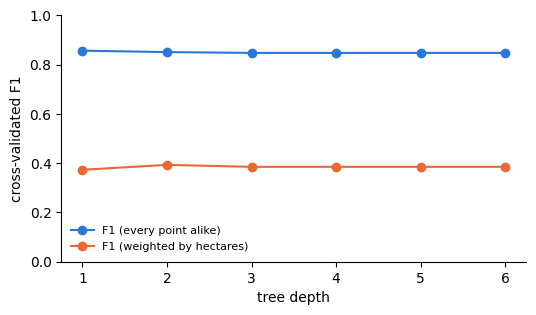

,f1,precision,recall,f1_weighted
1,0.856,0.820,0.899,0.373
2,0.851,0.823,0.883,0.393
3,0.847,0.818,0.882,0.385
4,0.847,0.818,0.882,0.385
5,0.847,0.818,0.882,0.385
6,0.847,0.818,0.882,0.385


In [4]:
# the same settings at every depth: where does a deeper tree stop helping?
sweep = pd.DataFrame({d: cv_scores({**PARAMS, "max_depth": d}, X, y, w).mean() for d in range(1, 7)}).T
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sweep.index, sweep.f1, marker="o", color="#2a78d6", label="F1 (every point alike)")
ax.plot(sweep.index, sweep.f1_weighted, marker="o", color="#eb6834", label="F1 (weighted by hectares)")
ax.set(xlabel="tree depth", ylabel="cross-validated F1", ylim=(0, 1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()
sweep.round(3)

## 3. The tree on all calibration points

crop if dist_buildings_m <= 333.4111 and edge_density > 0.0937 and vh_range <= 9.5863
crop if dist_buildings_m <= 333.4111 and edge_density > 0.0937 and vh_range > 9.5863
otherwise not crop


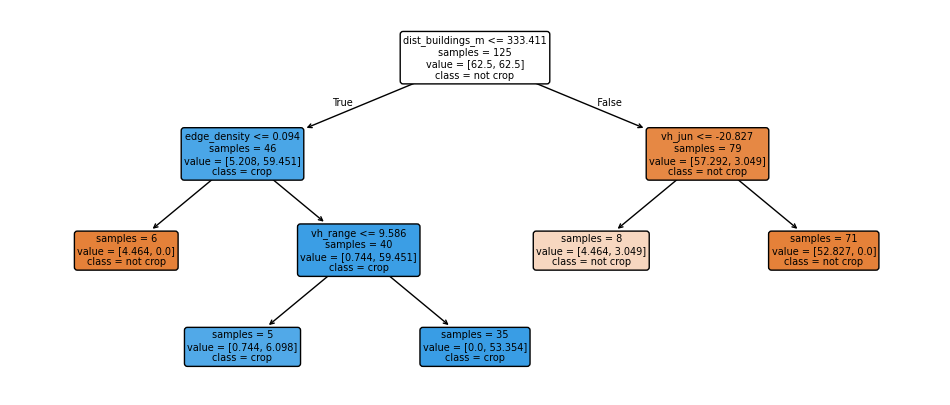

dist_buildings_m    0.819
edge_density        0.141
vh_jun              0.038
vh_range            0.002
bsi_max_am          0.000
ndvi_min_am         0.000
drop_vs_500m        0.000
ndvi_peak_jja       0.000
Name: importance, dtype: float64

In [5]:
tree = DecisionTreeClassifier(random_state=C.SEED, **PARAMS).fit(X, y)
ruleset = R.from_tree(tree, INPUTS, fill, NAME)       # the same rules the Earth Engine map would use
print(R.as_text(ruleset))
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(tree, feature_names=INPUTS, class_names=["not crop", "crop"], filled=True, impurity=False,
          rounded=True, fontsize=7, ax=ax)
plt.show()
pd.Series(tree.feature_importances_, INPUTS).sort_values(ascending=False).head(8).round(3).rename("importance")

## 4. Rule 1, retrained from scratch

Rule 1 came from `07_fit_rules.py`: target "crop", both areas, all 18 features, `min_samples_leaf=5`,
`class_weight="balanced"`, depth chosen from 2, 3 or 4 by 5-fold cross-validation (smallest depth within 0.02
F1 of the best). Fitting that again gives exactly the frozen rule.

In [6]:
rule1 = R.load(C.HERE / "rule1_2026-10-12.json")
Xr, yr, _ = M.load("calibration", target="crop")
again = DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, class_weight="balanced", random_state=C.SEED)
again = R.from_tree(again.fit(Xr.fillna(rule1["fill"]).to_numpy(), yr), F.FEATURES, rule1["fill"], "rule1")
print(R.as_text(rule1))
print("retrained = frozen Rule 1:", again["rules"] == rule1["rules"])

crop if dist_buildings_m <= 333.4111 and edge_density > 0.0937
otherwise not crop
retrained = frozen Rule 1: True


## 5. Freeze (only once, after logging it in METHODOLOGY.md)

Writes the rules file (which `08_run_map.py` can map) and the predictions for all 450 points from their box
features. Nothing is written while `FREEZE = False`.

In [7]:
FREEZE = False

if FREEZE:
    out = C.HERE / "results" / f"predictions_{NAME}.csv"
    assert not out.exists(), f"{out.name} exists: a tree with this name is frozen already"
    saved = R.save(ruleset, C.HERE)
    t = pd.read_csv(M.TABLE)
    pd.DataFrame({"id": t.id, "prediction": R.predict(ruleset, t)}).to_csv(out, index=False)
    print(f"saved {saved.name} and results/{out.name}; next: python cropland/09_score.py cropland/rule1_2026-10-12.json")
else:
    print("not frozen: nothing written")

not frozen: nothing written
